
# DSC212 Research Assignment
## Modularity on the Karate Club Graph

**Objective.** Implement recursive spectral modularity partitioning from the assignment handout, visualize every accepted split, compute node metrics after each split, and discuss the results.

### Method used
The handout defines the global modularity matrix as

\[
B=A-\frac{kk^\top}{2m},
\]

where \(A\) is the adjacency matrix, \(k\) is the degree vector, and \(m\) is the number of edges. For a current community \(C\), this notebook takes the corresponding principal submatrix \(B^{(C)}=B[C,C]\), exactly as specified in Sections 3.3 and 4 of the handout. Its largest eigenpair determines the split: positive eigenvector entries go to one child and nonpositive entries to the other. A community is not split if its largest eigenvalue is nonpositive or if the sign split is empty.

**Metric convention.** The graph itself is not rewired or deleted during community detection. To make the requested metric-evolution plots informative, each node's four metrics are calculated on the *induced subgraph of the community to which that node currently belongs*. Thus, values describe a node's position within its current community, not in the unchanged full graph.

The notebook uses NetworkX, NumPy, Matplotlib, and pandas.


In [1]:

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib import cm
from IPython.display import display

plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("NetworkX version:", nx.__version__)


NetworkX version: 3.6.1



## 1. Load the Karate Club graph

Zachary's Karate Club graph is an undirected, unweighted social network with 34 members and 78 edges. Node IDs are retained throughout the analysis.


Number of nodes = 34
Number of edges = 78
Is the graph undirected? True


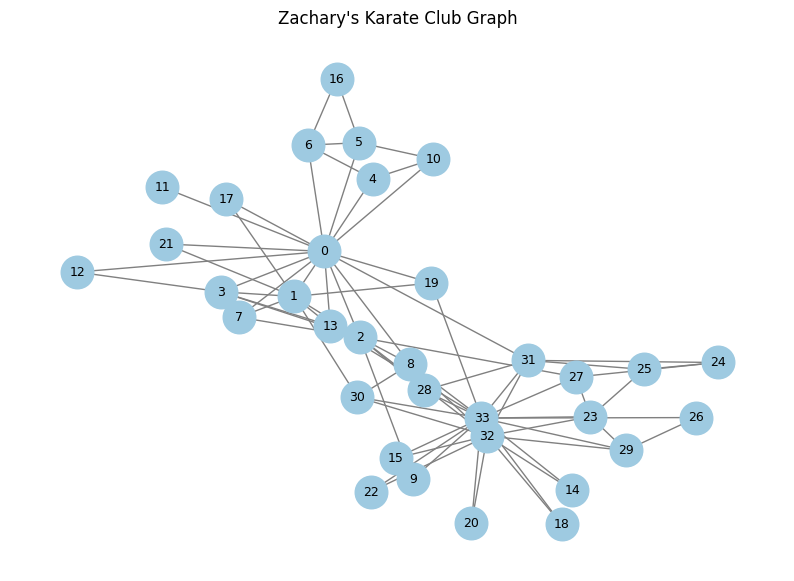

In [2]:

G = nx.karate_club_graph()
nodes = sorted(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

print(f"Number of nodes = {n}")
print(f"Number of edges = {m}")
print("Is the graph undirected?", not G.is_directed())

# A fixed layout is reused in every later graph visualization.
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 7))
nx.draw_networkx(
    G, pos=pos, node_color="#9ecae1", edge_color="gray",
    node_size=550, font_size=9, with_labels=True
)
plt.title("Zachary's Karate Club Graph")
plt.axis("off")
plt.show()



## 2. Construct the modularity matrix

The adjacency matrix entry \(A_{ij}\) is 1 when nodes \(i\) and \(j\) are adjacent, and 0 otherwise. The degree of node \(i\) is \(k_i=\sum_j A_{ij}\), and \(\sum_i k_i=2m\).

\[
B_{ij}=A_{ij}-\frac{k_i k_j}{2m}.
\]

The first term is the observed adjacency; the second is the expected adjacency under the degree-preserving random null model described in the handout.


In [3]:

# NetworkX stores historical interaction weights on edges; the assignment uses an unweighted graph.
A = nx.to_numpy_array(G, nodelist=nodes, weight=None, dtype=float)
degree = A.sum(axis=1)
B = A - np.outer(degree, degree) / (2 * m)

print("Adjacency matrix shape:", A.shape)
print("Modularity matrix shape:", B.shape)
print("Maximum asymmetry |B - B.T|:", np.max(np.abs(B - B.T)))
print("Maximum absolute row sum (should be close to 0):",
      np.max(np.abs(B.sum(axis=1))))

display(pd.DataFrame(B, index=nodes, columns=nodes).round(3).iloc[:6, :6])


Adjacency matrix shape: (34, 34)
Modularity matrix shape: (34, 34)
Maximum asymmetry |B - B.T|: 0.0
Maximum absolute row sum (should be close to 0): 8.881784197001252e-16


,0,1,2,3,4,5
0,-1.641,0.077,-0.026,0.385,0.692,0.590
1,0.077,-0.519,0.423,0.654,-0.173,-0.231
2,-0.026,0.423,-0.641,0.615,-0.192,-0.256
3,0.385,0.654,0.615,-0.231,-0.115,-0.154
4,0.692,-0.173,-0.192,-0.115,-0.058,-0.077
5,0.590,-0.231,-0.256,-0.154,-0.077,-0.103



## 3. Recursive spectral modularity partitioning

For a community \(C\), take the block of the *global* modularity matrix whose rows and columns correspond to nodes in \(C\). Compute its leading eigenpair \((\lambda_1,u_1)\).

- If \(\lambda_1\leq 0\), stop splitting this community.
- Otherwise, assign nodes with \(u_{1,i}>0\) to the positive child and nodes with \(u_{1,i}\leq 0\) to the other child.
- Recurse on both children.

The modularity matrix is real and symmetric, so `numpy.linalg.eigh` is appropriate: it returns real eigenvalues and orthonormal eigenvectors. The largest eigenvalue is the last element of the ascending eigenvalue array.


In [4]:

# Map each node ID to its row/column index in the global matrix.
node_to_index = {node: i for i, node in enumerate(nodes)}

def restricted_modularity_matrix(community):
    """Return the principal submatrix B[C,C] for a community C."""
    indices = [node_to_index[v] for v in community]
    return B[np.ix_(indices, indices)]


def recursive_spectral_partition(initial_nodes, tolerance=1e-10):
    """
    Recursively split communities using the leading eigenvector of B[C,C].

    Returns
    -------
    final_communities : list[list]
        Communities remaining after all accepted splits.
    snapshots : list[list[list]]
        Partition after iteration 0 (before splitting), then after each split.
    split_log : list[dict]
        Details of each attempted split.
    """
    initial_community = sorted(initial_nodes)
    snapshots = [[initial_community.copy()]]
    split_log = []
    final_communities = []

    def recurse(community):
        community = sorted(community)

        # A one-node group cannot be split into two nonempty groups.
        if len(community) < 2:
            final_communities.append(community)
            return

        Bc = restricted_modularity_matrix(community)
        eigenvalues, eigenvectors = np.linalg.eigh(Bc)
        leading_value = float(eigenvalues[-1])
        leading_vector = eigenvectors[:, -1]

        # The handout's stopping criterion.
        if leading_value <= tolerance:
            split_log.append({
                "community": community.copy(),
                "lambda_max": leading_value,
                "status": "stopped: nonpositive eigenvalue"
            })
            final_communities.append(community)
            return

        positive_child = [
            community[i] for i, value in enumerate(leading_vector)
            if value > 0
        ]
        nonpositive_child = [
            community[i] for i, value in enumerate(leading_vector)
            if value <= 0
        ]

        # Guard against a degenerate sign split.
        if len(positive_child) == 0 or len(nonpositive_child) == 0:
            split_log.append({
                "community": community.copy(),
                "lambda_max": leading_value,
                "status": "stopped: degenerate sign split"
            })
            final_communities.append(community)
            return

        split_log.append({
            "community": community.copy(),
            "lambda_max": leading_value,
            "status": "split",
            "positive_child": sorted(positive_child),
            "nonpositive_child": sorted(nonpositive_child)
        })

        # Replace the parent community by its two children in the current partition.
        current_partition = snapshots[-1]
        remaining = [c for c in current_partition if c != community]
        new_partition = remaining + [sorted(positive_child), sorted(nonpositive_child)]
        new_partition = sorted(new_partition, key=lambda c: (min(c), len(c)))
        snapshots.append([c.copy() for c in new_partition])

        # Continue recursively. The next accepted split will update the snapshot.
        recurse(positive_child)
        recurse(nonpositive_child)

    recurse(initial_community)

    # Sort final groups for a stable, readable output.
    final_communities = sorted(final_communities, key=lambda c: (min(c), len(c)))
    return final_communities, snapshots, split_log


final_communities, partition_snapshots, split_log = recursive_spectral_partition(nodes)

print("Number of accepted splits:", sum(x["status"] == "split" for x in split_log))
print("Number of final communities:", len(final_communities))
print("Final community sizes:", [len(c) for c in final_communities])
print("All nodes accounted for exactly once:",
      sorted(v for c in final_communities for v in c) == nodes)


Number of accepted splits: 4
Number of final communities: 5
Final community sizes: [10, 5, 13, 1, 5]
All nodes accounted for exactly once: True



## 4. Visualize the graph after every split

The same spring-layout coordinates are used in every panel. Only node colours change, so the movement of nodes is not confused with a change in layout. Each community receives a different colour, and node IDs remain visible.


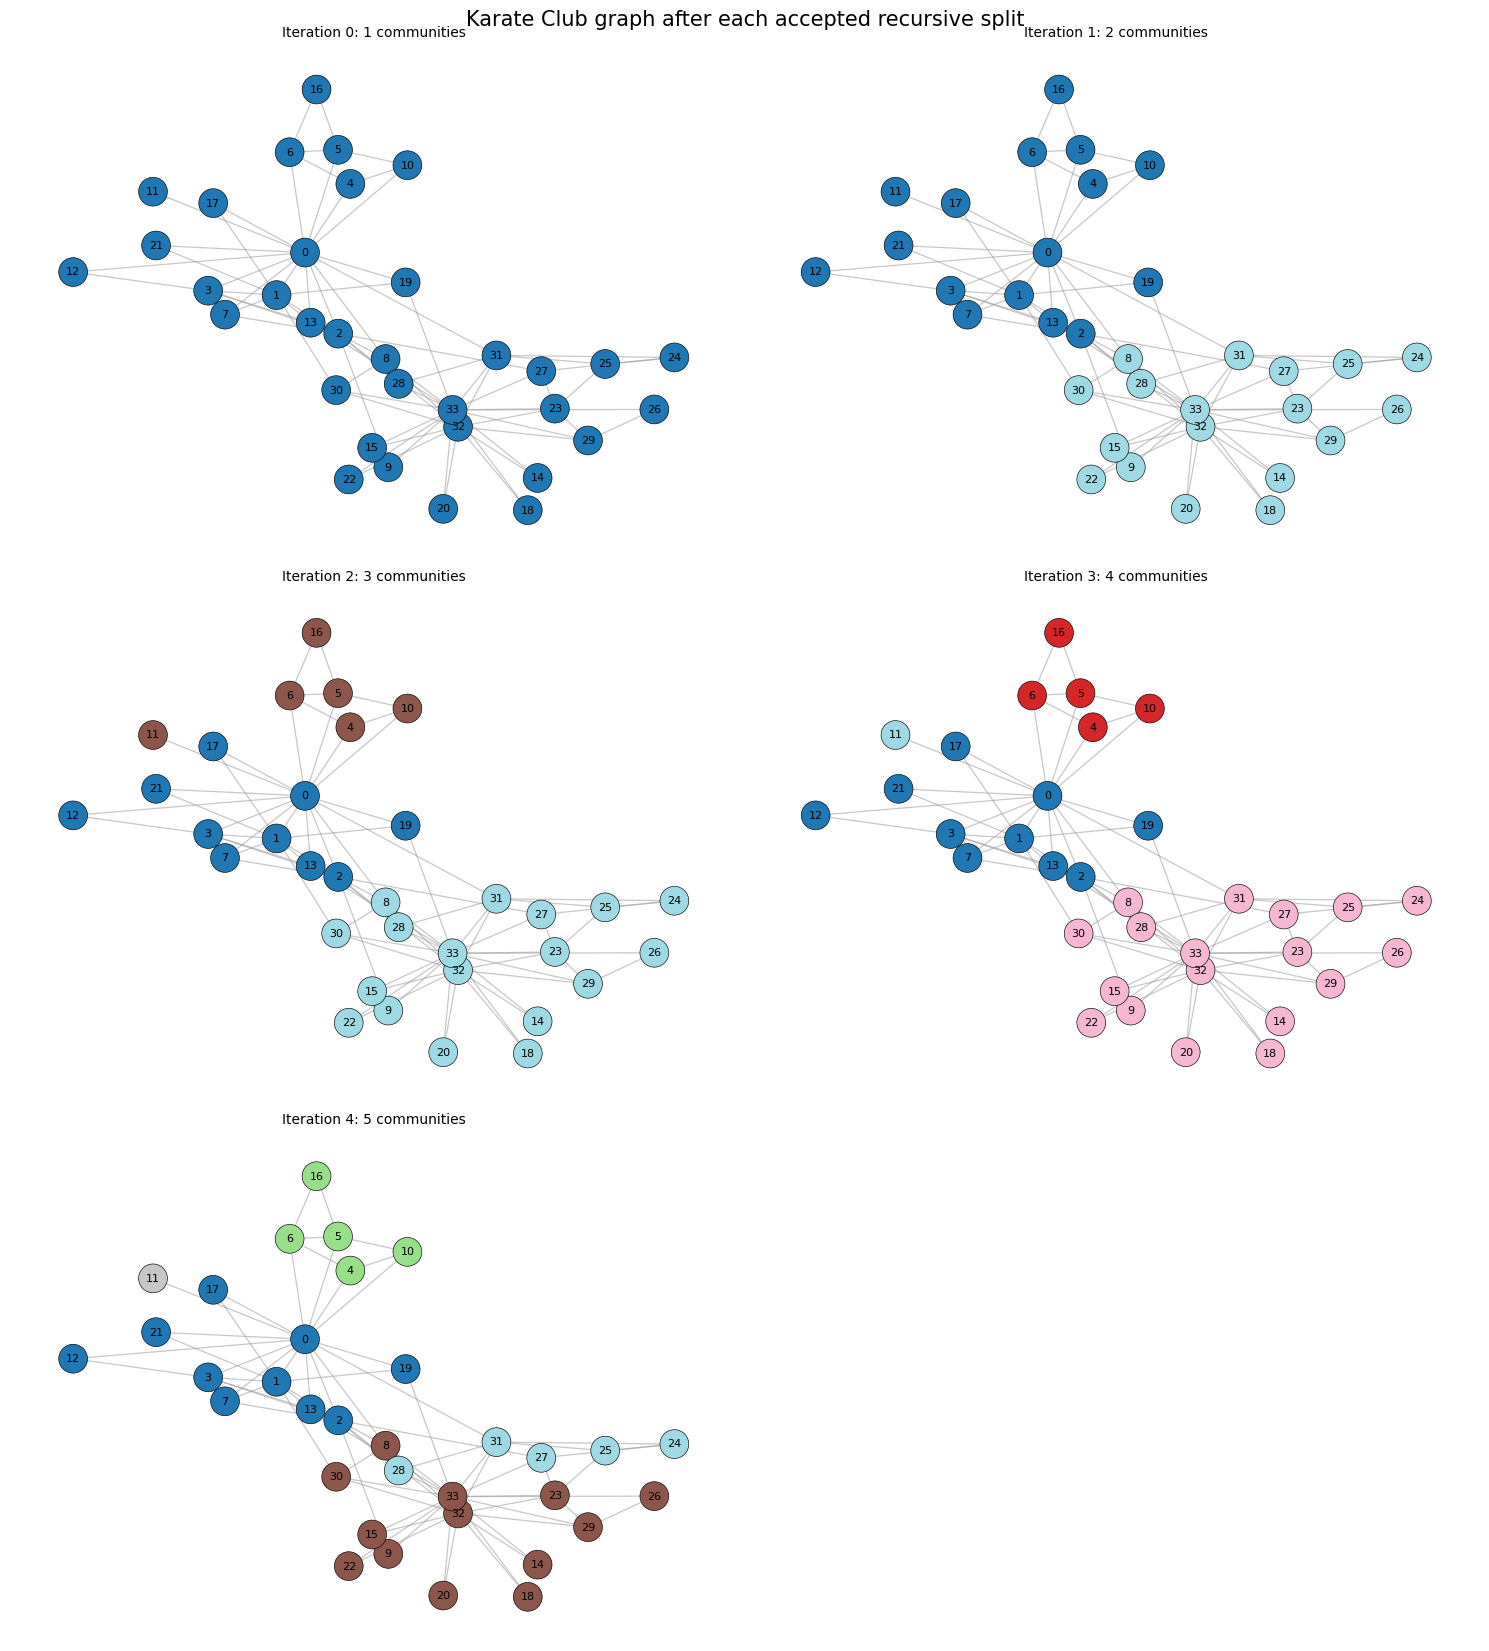

In [5]:

def draw_partition(ax, partition, title):
    """Draw the original graph, colouring nodes by their current community."""
    palette = plt.get_cmap("tab20", max(len(partition), 1))
    node_colors = {}
    for community_id, community in enumerate(partition):
        for node in community:
            node_colors[node] = palette(community_id)

    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color="#999999", alpha=0.55, width=0.9)
    nx.draw_networkx_nodes(
        G, pos=pos, ax=ax, node_color=[node_colors[v] for v in nodes],
        node_size=430, edgecolors="black", linewidths=0.45
    )
    nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=8)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


number_of_panels = len(partition_snapshots)
columns = 2
rows = int(np.ceil(number_of_panels / columns))
fig, axes = plt.subplots(rows, columns, figsize=(15, 5.6 * rows))
axes = np.array(axes).reshape(-1)

for i, partition in enumerate(partition_snapshots):
    draw_partition(
        axes[i], partition,
        f"Iteration {i}: {len(partition)} communities"
    )

for j in range(number_of_panels, len(axes)):
    axes[j].axis("off")

fig.suptitle("Karate Club graph after each accepted recursive split", fontsize=15)
plt.tight_layout()
plt.show()



## 5. Record the split history

The table below reports the largest eigenvalue for every community that was tested. A positive value with a nondegenerate sign split results in two child communities; otherwise recursion stops on that group.


In [6]:

split_rows = []
for entry in split_log:
    split_rows.append({
        "tested community": str(entry["community"]),
        "size": len(entry["community"]),
        "largest eigenvalue": entry["lambda_max"],
        "decision": entry["status"]
    })

split_history = pd.DataFrame(split_rows)
display(split_history.round({"largest eigenvalue": 6}))


,tested community,size,largest eigenvalue,decision
0,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",34,4.977080,split
1,"[0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 1...",16,2.944129,split
2,"[0, 1, 2, 3, 7, 12, 13, 17, 19, 21]",10,2.571158,stopped: degenerate sign split
3,"[4, 5, 6, 10, 11, 16]",6,2.147993,split
4,"[4, 5, 6, 10, 16]",5,2.147005,stopped: degenerate sign split
5,"[8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27,...",18,2.504088,split
6,"[24, 25, 27, 28, 31]",5,1.875925,stopped: degenerate sign split
7,"[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32,...",13,2.356350,stopped: degenerate sign split



## 6. Compute node metrics after each split

For each partition snapshot, every community is converted to its induced subgraph. The following NetworkX functions are used:

1. `nx.degree_centrality(H)`
2. `nx.betweenness_centrality(H)`
3. `nx.closeness_centrality(H)`
4. `nx.clustering(H)`

Here \(H\) is the induced subgraph of the node's current community. A node's metric values can therefore change when its community is subdivided, even though the original Karate Club graph remains unchanged.


In [7]:

metric_names = [
    "degree_centrality",
    "betweenness_centrality",
    "closeness_centrality",
    "clustering"
]

metric_snapshots = []

for iteration, partition in enumerate(partition_snapshots):
    values = {
        node: {metric: 0.0 for metric in metric_names}
        for node in nodes
    }
    community_of = {}

    for community_id, community in enumerate(partition):
        H = G.subgraph(community).copy()

        degree_values = nx.degree_centrality(H)
        betweenness_values = nx.betweenness_centrality(H, normalized=True)
        closeness_values = nx.closeness_centrality(H)
        clustering_values = nx.clustering(H)

        for node in community:
            community_of[node] = community_id
            values[node]["degree_centrality"] = degree_values[node]
            values[node]["betweenness_centrality"] = betweenness_values[node]
            values[node]["closeness_centrality"] = closeness_values[node]
            values[node]["clustering"] = clustering_values[node]

    for node in nodes:
        values[node]["iteration"] = iteration
        values[node]["community"] = community_of[node]
        values[node]["node"] = node

    metric_snapshots.append(pd.DataFrame([values[node] for node in nodes]))

metrics_long = pd.concat(metric_snapshots, ignore_index=True)
display(metrics_long.head(10).round(4))


,degree_centrality,betweenness_centrality,closeness_centrality,clustering,iteration,community,node
0,0.4848,0.4376,0.5690,0.1500,0,0,0
1,0.2727,0.0539,0.4853,0.3333,0,0,1
2,0.3030,0.1437,0.5593,0.2444,0,0,2
3,0.1818,0.0119,0.4648,0.6667,0,0,3
4,0.0909,0.0006,0.3793,0.6667,0,0,4
5,0.1212,0.0300,0.3837,0.5000,0,0,5
6,0.1212,0.0300,0.3837,0.5000,0,0,6
7,0.1212,0.0000,0.4400,1.0000,0,0,7
8,0.1515,0.0559,0.5156,0.5000,0,0,8
9,0.0606,0.0008,0.4342,0.0000,0,0,9



## 7. Plot metric evolution for every node

Each line represents one node. The horizontal axis is the partition iteration (0 is the original, unsplit graph). Values are calculated within each node's current community at that iteration.


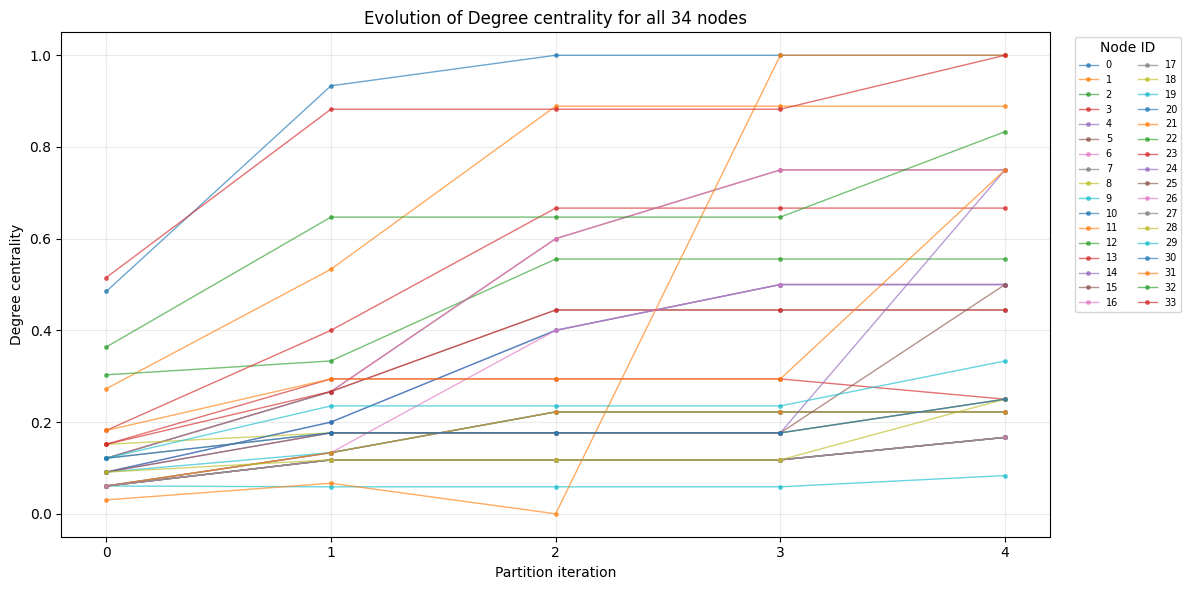

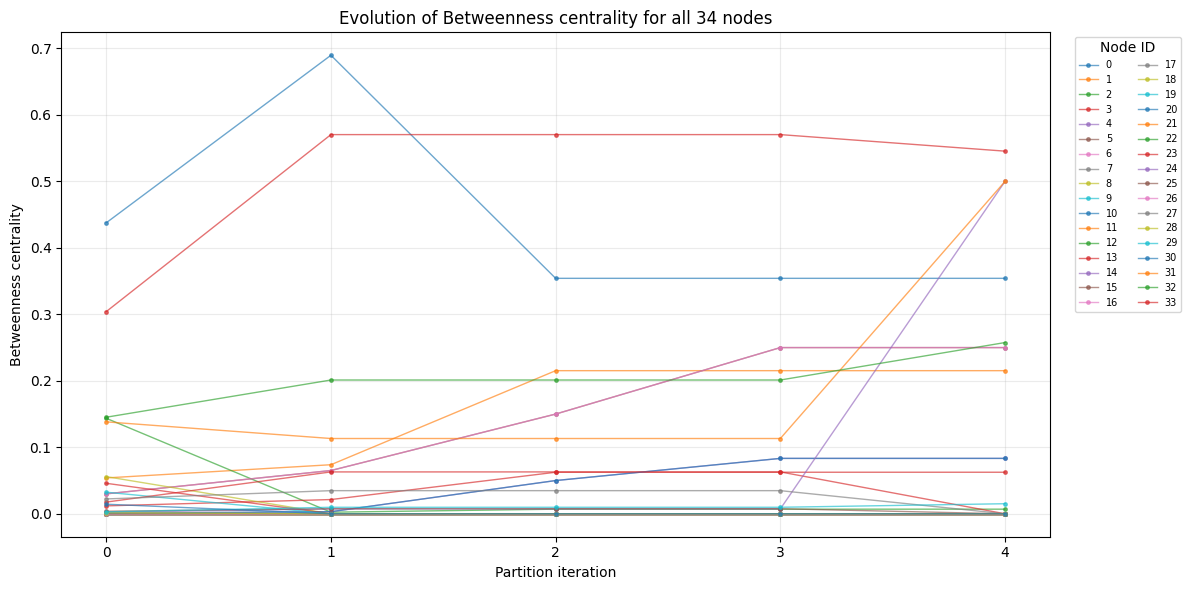

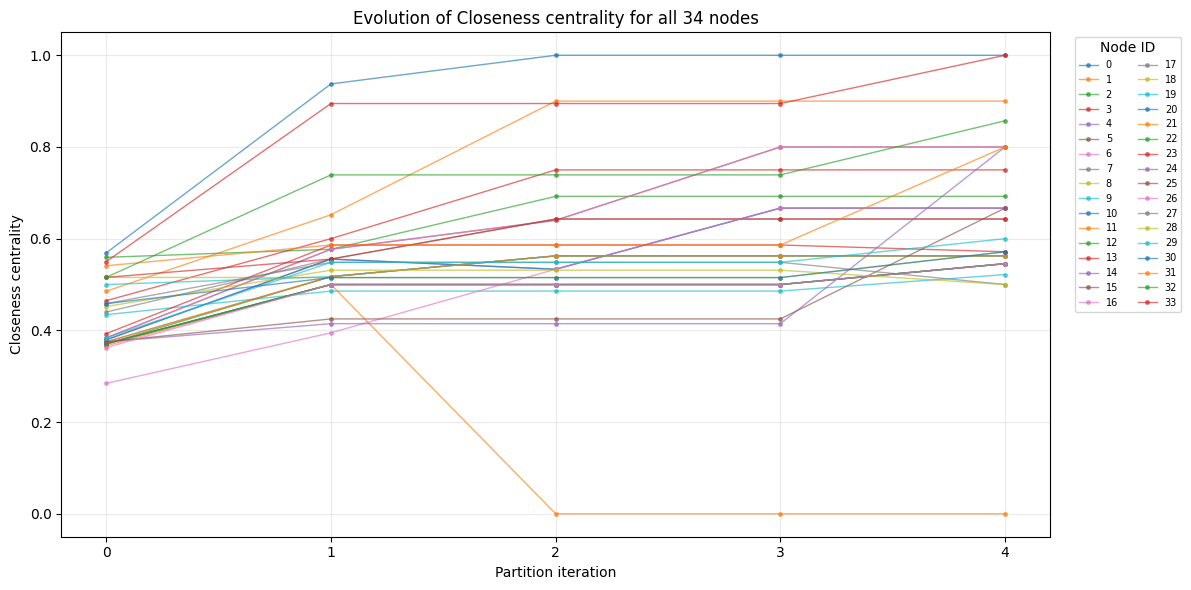

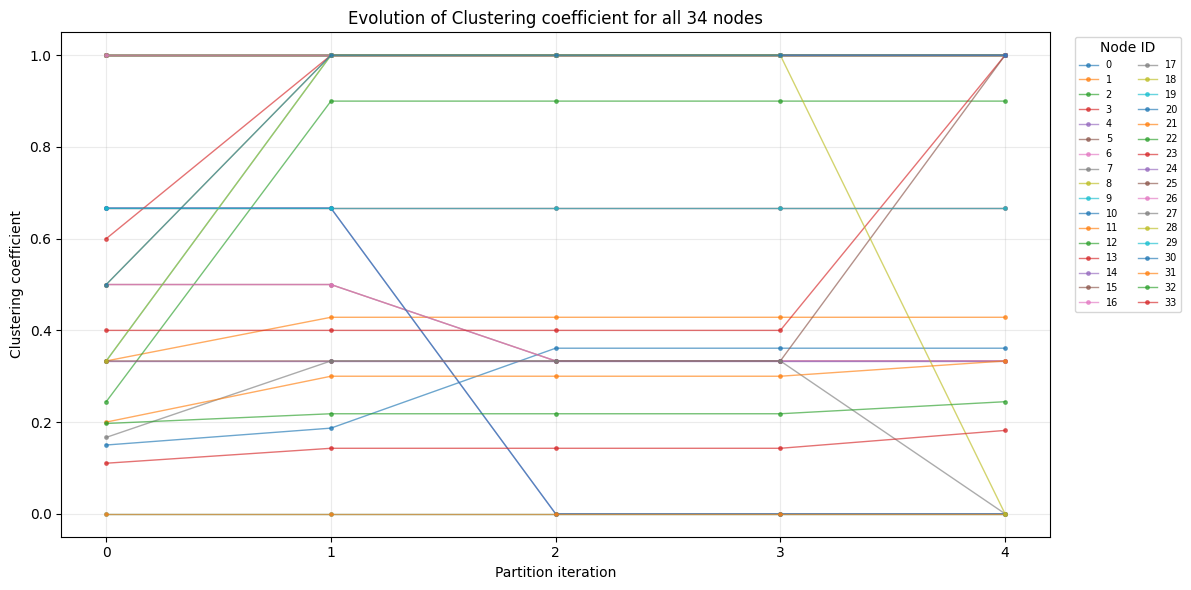

In [8]:

metric_titles = {
    "degree_centrality": "Degree centrality",
    "betweenness_centrality": "Betweenness centrality",
    "closeness_centrality": "Closeness centrality",
    "clustering": "Clustering coefficient"
}

for metric in metric_names:
    pivot = metrics_long.pivot(index="iteration", columns="node", values=metric)
    plt.figure(figsize=(12, 6))
    for node in nodes:
        plt.plot(
            pivot.index, pivot[node],
            marker="o", markersize=2.5, linewidth=1, alpha=0.65,
            label=str(node)
        )
    plt.xlabel("Partition iteration")
    plt.ylabel(metric_titles[metric])
    plt.title(f"Evolution of {metric_titles[metric]} for all 34 nodes")
    plt.xticks(range(len(partition_snapshots)))
    plt.legend(
        title="Node ID", bbox_to_anchor=(1.02, 1),
        loc="upper left", ncol=2, fontsize=7
    )
    plt.tight_layout()
    plt.show()



## 8. Identify consistently important nodes

The first table ranks nodes by their metrics in the original full graph. The second table shows the final within-community metrics. The original graph's degree ranking is useful for identifying hubs; betweenness highlights bridges, while closeness and clustering describe reachability and local cohesion.


In [9]:

initial_metrics = metrics_long[metrics_long["iteration"] == 0].set_index("node")
final_metrics = metrics_long[metrics_long["iteration"] == len(partition_snapshots) - 1].set_index("node")

initial_ranking = initial_metrics[metric_names].copy()
initial_ranking["club faction (dataset attribute)"] = [
    G.nodes[v].get("club", "unknown") for v in initial_ranking.index
]
print("Top 10 nodes by degree centrality in the original graph:")
display(initial_ranking.sort_values("degree_centrality", ascending=False).head(10).round(4))

comparison = pd.DataFrame({
    "initial degree": initial_metrics["degree_centrality"],
    "final within-community degree": final_metrics["degree_centrality"],
    "initial betweenness": initial_metrics["betweenness_centrality"],
    "final within-community betweenness": final_metrics["betweenness_centrality"],
    "final community": final_metrics["community"].astype(int)
})
print("Selected initial-to-final metric comparison:")
display(comparison.sort_values("initial degree", ascending=False).head(12).round(4))


Top 10 nodes by degree centrality in the original graph:


,degree_centrality,betweenness_centrality,closeness_centrality,clustering,club faction (dataset attribute)
node,,,,,
33,0.5152,0.3041,0.5500,0.1103,Officer
0,0.4848,0.4376,0.5690,0.1500,Mr. Hi
32,0.3636,0.1452,0.5156,0.1970,Officer
2,0.3030,0.1437,0.5593,0.2444,Mr. Hi
1,0.2727,0.0539,0.4853,0.3333,Mr. Hi
3,0.1818,0.0119,0.4648,0.6667,Mr. Hi
31,0.1818,0.1383,0.5410,0.2000,Officer
23,0.1515,0.0176,0.3929,0.4000,Officer
8,0.1515,0.0559,0.5156,0.5000,Mr. Hi


Selected initial-to-final metric comparison:


,initial degree,final within-community degree,initial betweenness,final within-community betweenness,final community
node,,,,,
33,0.5152,1.0000,0.3041,0.5455,2
0,0.4848,1.0000,0.4376,0.3542,0
32,0.3636,0.8333,0.1452,0.2576,2
2,0.3030,0.5556,0.1437,0.0069,0
1,0.2727,0.8889,0.0539,0.2153,0
3,0.1818,0.6667,0.0119,0.0625,0
31,0.1818,0.7500,0.1383,0.5000,4
23,0.1515,0.2500,0.0176,0.0000,2
8,0.1515,0.2500,0.0559,0.0000,2



## 9. Final detected communities

The following table lists the nodes assigned to each final community. These are the output of the recursive algorithm specified in the handout; they are not manually matched to the historical faction labels.


In [10]:

community_table = pd.DataFrame({
    "Community": [f"C{i+1}" for i in range(len(final_communities))],
    "Number of nodes": [len(c) for c in final_communities],
    "Node IDs": [", ".join(map(str, c)) for c in final_communities]
})
display(community_table)


,Community,Number of nodes,Node IDs
0,C1,10,"0, 1, 2, 3, 7, 12, 13, 17, 19, 21"
1,C2,5,"4, 5, 6, 10, 16"
2,C3,13,"8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33"
3,C4,1,11
4,C5,5,"24, 25, 27, 28, 31"



## 10. Discussion

### Which nodes remain central?

In the original Karate Club graph, high-degree nodes are the immediate hubs. In particular, nodes **0, 33, 32, 2, and 1** are among the most connected vertices (the exact ranking is printed in the table above). Nodes with high betweenness are important because many shortest paths pass through them; such nodes can connect otherwise weakly connected parts of the network.

### How does community structure influence the metrics?

At iteration 0, all metrics are calculated on the full graph. After a community is split, each node is measured only against the nodes remaining in its own community. Consequently:

- Degree centrality generally decreases when a node loses neighbours that are assigned to another community.
- Betweenness can decrease when shortest paths that previously passed through a node are separated into different communities.
- Closeness changes because the set of nodes and shortest-path distances considered for a node changes.
- Clustering can increase or decrease: removing neighbours may leave a more tightly connected local group, or may remove triangles that contributed to the coefficient.

The plots show that nodes which are hubs in the full network do not necessarily remain equally central inside every smaller community. A node can be globally important because it connects communities, but become less important when the analysis is restricted to one community. Conversely, a node with modest global degree can have high centrality within a small, dense community.

### Interpretation and limitation

The method follows the handout's stated rule: use the principal submatrix \(B[C,C]\) of the global modularity matrix for each current community, and stop when its largest eigenvalue is nonpositive. The resulting number and sizes of communities are therefore specific to this prescribed implementation and its sign-thresholding rule. The sign of an eigenvector is arbitrary (multiplying the whole eigenvector by \(-1\) swaps the two child labels but does not change the split).

**Important distinction:** the graph is never physically cut when computing the metric snapshots; metrics are evaluated on induced community subgraphs so that their evolution reflects the changing community membership. If instead one computes NetworkX metrics on the unchanged full graph at every iteration, the metric values would be identical at every iteration.




## 11. Reference

Newman, M. E. J. (2006). *Modularity and community structure in networks*. Proceedings of the National Academy of Sciences, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103

The definitions of modularity, the modularity matrix, and the spectral bipartition approach in this notebook follow the assignment handout and the above reference.
